# Phase 1 — Data Preprocessing & Feature Engineering
**Student:** Jeswin Tobias J &nbsp;|&nbsp; **Roll No:** CS23I1013
**Course:** Analytics & Systems of Big Data Practice — End-Sem Hackathon
**Dataset:** Power Consumption of Tetouan City, Morocco (UCI #849) — 10-min readings, 2017

KDD steps covered here:
1. **Cleaning** — remove noisy / invalid readings
2. **Feature engineering** — derive attributes the later tasks need
3. **Selection** — keep task-relevant, non-redundant attributes
4. **Transformation** — scale, discretise and reshape data for DIC/COFI, KNN and DIANA

Outputs go to `outputs/`; every figure goes to `plots/`.

In [1]:
import sys; sys.path.append('..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.feature_selection import mutual_info_classif
from src.common import *

set_style(); header()
pd.set_option('display.width', 160, 'display.max_columns', 40)

Jeswin Tobias J | CS23I1013 | ASBD Hackathon — Tetouan Power Consumption


## 1. Load & Inspect

In [2]:
df = load_raw()
print(df.shape)
df.head()

(52416, 9)


,datetime,temperature,humidity,wind_speed,gen_diffuse,diffuse,zone1,zone2,zone3
0,2017-01-01 00:00:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386
1,2017-01-01 00:10:00,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434
2,2017-01-01 00:20:00,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373
3,2017-01-01 00:30:00,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711
4,2017-01-01 00:40:00,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964


In [3]:
df.describe().T.round(2)

,count,mean,min,25%,50%,75%,max,std
datetime,52416,2017-07-01 23:55:00,2017-01-01 00:00:00,2017-04-01 23:57:30,2017-07-01 23:55:00,2017-09-30 23:52:30,2017-12-30 23:50:00,NaN
temperature,52416.0,18.810024,3.247,14.41,18.78,22.89,40.01,5.815476
humidity,52416.0,68.259518,11.34,58.31,69.86,81.4,94.8,15.551177
wind_speed,52416.0,1.959489,0.05,0.078,0.086,4.915,6.483,2.348862
gen_diffuse,52416.0,182.696614,0.004,0.062,5.0355,319.6,1163.0,264.40096
diffuse,52416.0,75.028022,0.011,0.122,4.456,101.0,936.0,124.210949
zone1,52416.0,32344.970564,13895.6962,26310.668692,32265.92034,37309.018185,52204.39512,7130.562564
zone2,52416.0,21042.509082,8560.081466,16980.766032,20823.168405,24713.71752,37408.86076,5201.465892
zone3,52416.0,17835.406218,5935.17407,13129.32663,16415.11747,21624.10042,47598.32636,6622.165099


In [4]:
# Data-quality checks: nulls, duplicates, gaps in the 10-min grid
full_grid = pd.date_range(df.datetime.min(), df.datetime.max(), freq='10min')
print('Null cells          :', df.isna().sum().sum())
print('Duplicate rows      :', df.duplicated().sum())
print('Duplicate timestamps:', df.datetime.duplicated().sum())
print('Missing 10-min slots:', len(full_grid.difference(df.datetime)))
print('Readings per day    :', df.groupby(df.datetime.dt.date).size().value_counts().to_dict())
print('Date range          :', df.datetime.min(), '->', df.datetime.max())

Null cells          : 0
Duplicate rows      : 0
Duplicate timestamps: 0
Missing 10-min slots: 0
Readings per day    : {144: 364}
Date range          : 2017-01-01 00:00:00 -> 2017-12-30 23:50:00


**Inference:** no nulls, duplicates or gaps — 364 complete days × 144 readings. Cleaning therefore targets **noise** (spikes, sensor floor), not missing data.

## 2. Cleaning
### 2.1 Validity rules
Physical bounds (assumed): temperature −10…50 °C, humidity 0…100 %, wind ≥ 0, irradiance ≥ 0, power > 0.

In [5]:
rules = {'temperature': (-10, 50), 'humidity': (0, 100), 'wind_speed': (0, np.inf),
         'gen_diffuse': (0, np.inf), 'diffuse': (0, np.inf),
         'zone1': (1e-9, np.inf), 'zone2': (1e-9, np.inf), 'zone3': (1e-9, np.inf)}
viol = {c: int((~df[c].between(lo, hi)).sum()) for c, (lo, hi) in rules.items()}
pd.Series(viol, name='violations').to_frame().T

,temperature,humidity,wind_speed,gen_diffuse,diffuse,zone1,zone2,zone3
violations,0,0,0,0,0,0,0,0


### 2.2 Why plain IQR removal is wrong here
IQR fences assume one stationary distribution. Power has strong **seasonal** level shifts, so IQR would delete genuine summer demand.

In [6]:
def iqr_mask(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return (s < q1 - 1.5*i) | (s > q3 + 1.5*i)

iqr = pd.DataFrame({c: iqr_mask(df[c]) for c in WEATHER + ZONES})
print('IQR flags per column:', iqr.sum().to_dict())
print('Zone-3 IQR flags by month:', df.loc[iqr.zone3, 'datetime'].dt.month.value_counts().sort_index().to_dict())

IQR flags per column: {'temperature': 142, 'humidity': 291, 'wind_speed': 0, 'gen_diffuse': 2315, 'diffuse': 4571, 'zone1': 0, 'zone2': 7, 'zone3': 1191}
Zone-3 IQR flags by month: {7: 760, 8: 431}


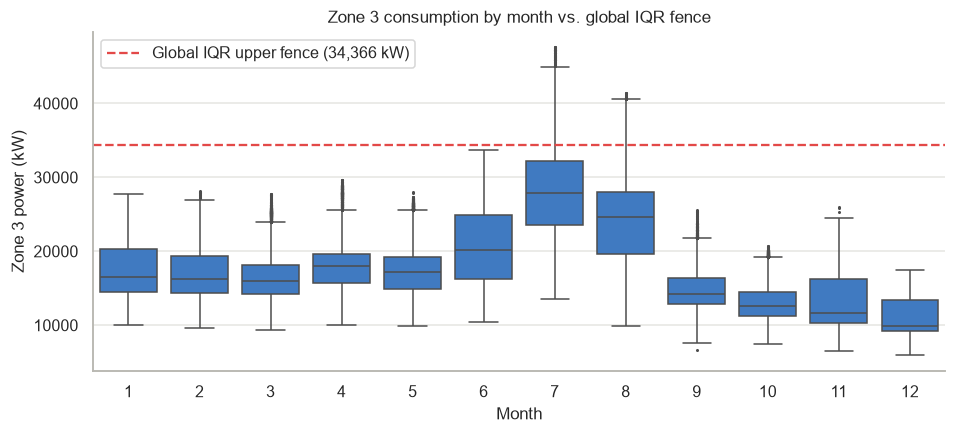

In [7]:
# Zone 3 by month with the global IQR upper fence
q1, q3 = df.zone3.quantile([.25, .75]); fence = q3 + 1.5*(q3 - q1)
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(x=df.datetime.dt.month, y=df.zone3, color=CAT[0], fliersize=1, linewidth=1, ax=ax)
ax.axhline(fence, color=CAT[7], ls='--', lw=1.5, label=f'Global IQR upper fence ({fence:,.0f} kW)')
ax.set(title='Zone 3 consumption by month vs. global IQR fence', xlabel='Month', ylabel='Zone 3 power (kW)')
ax.legend(loc='upper left')
save_fig('01_iqr_fence_zone3_by_month'); plt.show()

**Inference:** every Zone-3 "outlier" falls in July–August — real peak-summer demand (coastal tourism), not noise. IQR is **not** used for removal; a local spike filter is used instead.

### 2.3 Spike removal — rolling-median filter (Hampel-type, fixed thresholds)
- Each reading is compared with the **median of the 7 readings centred on it** (itself ± 30 min). If it deviates by more than a fixed threshold, it is a spike and is replaced by that median.
- Thresholds (assumed): power ±15 % of the local median, temperature ±2 °C, humidity ±10 %RH.
- **Why not the classic Hampel rule (3 × scaled MAD)?** In a 1-hour window these series are smooth, so the MAD is close to 0 and the classic rule flags 6,300–7,450 readings *per column* (≈ 13 %, checked below) — normal variation, not spikes. Fixed physical thresholds flag only true outliers.
- The first and last 3 readings of the year have no full window and are left unchanged.
- Irradiance is **not** filtered — fast changes there are real cloud transients.

In [8]:
def hampel(s, thr, relative=False, window=7):
    # Returns (cleaned series, spike mask)
    med = s.rolling(window, center=True, min_periods=window).median()   # full window only: no edge artefacts
    dev = (s - med).abs() / med if relative else (s - med).abs()
    mask = dev > thr
    return s.where(~mask, med), mask

HAMPEL = {'zone1': (0.15, True), 'zone2': (0.15, True), 'zone3': (0.15, True),
          'temperature': (2.0, False), 'humidity': (10.0, False)}
# Evidence for the fixed thresholds: what the classic MAD rule would flag
classic = {}
for c in HAMPEL:
    med = df[c].rolling(7, center=True).median(); mad = (df[c] - med).abs().rolling(7, center=True).median()
    classic[c] = int(((df[c] - med).abs() > 3 * 1.4826 * mad).sum())
print('Classic Hampel (3 x scaled MAD) would flag:', classic)

raw = df.copy()
spikes = {}
for c, (thr, rel) in HAMPEL.items():
    df[c], spikes[c] = hampel(df[c], thr, rel)
print('Spikes replaced:', {c: int(m.sum()) for c, m in spikes.items()})
raw.loc[spikes['zone1'] | spikes['zone2'] | spikes['zone3'], ['datetime'] + ZONES]

Classic Hampel (3 x scaled MAD) would flag: {'zone1': 6826, 'zone2': 6652, 'zone3': 6303, 'temperature': 6596, 'humidity': 7448}
Spikes replaced: {'zone1': 4, 'zone2': 1, 'zone3': 10, 'temperature': 2, 'humidity': 5}


,datetime,zone1,zone2,zone3
15769,2017-04-20 12:10:00,16814.98385,21471.69043,19450.181820
15770,2017-04-20 12:20:00,17794.61787,21563.34012,19781.818180
20525,2017-05-23 12:50:00,37808.26230,23386.99690,15513.522270
21370,2017-05-29 09:40:00,29121.04918,18479.25697,10884.534410
21669,2017-05-31 11:30:00,25318.81967,20574.61300,15618.461540
34716,2017-08-30 02:00:00,18283.68479,17247.30729,16642.006270
38913,2017-09-28 05:30:00,27621.23894,17476.09148,8131.072523
38914,2017-09-28 05:40:00,26359.64602,16873.59667,6707.252298
45173,2017-11-10 16:50:00,30172.30769,24887.60331,13480.481930
45261,2017-11-11 07:30:00,20824.61538,16051.23967,9027.469880


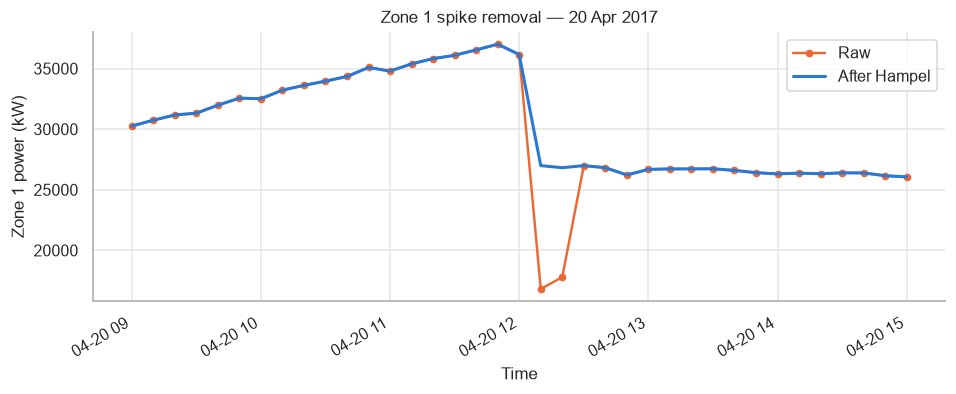

In [9]:
# Before/after for the largest spike (zone 1, 20-Apr-2017 midday)
win = (raw.datetime >= '2017-04-20 09:00') & (raw.datetime <= '2017-04-20 15:00')
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(raw.loc[win, 'datetime'], raw.loc[win, 'zone1'], color=CAT[1], marker='o', ms=4, label='Raw')
ax.plot(df.loc[win, 'datetime'], df.loc[win, 'zone1'], color=CAT[0], lw=2, label='After Hampel')
ax.set(title='Zone 1 spike removal — 20 Apr 2017', xlabel='Time', ylabel='Zone 1 power (kW)')
ax.legend(); fig.autofmt_xdate()
save_fig('02_hampel_spike_removal'); plt.show()

**Inference:** at 12:00 Zone 1 genuinely steps down (≈37k → 27k kW, likely a load transfer) — the filter keeps this level shift and removes only the two readings that drop to ≈17k below it. Just 15 power and 7 weather readings change in the whole year.

### 2.4 Irradiance sensor floor (cutoff = 1 W/m²)
- At night (22:00–04:59) both sensors read small non-zero values instead of 0 — sensor dark noise (night maximum checked below).
- **Cutoff 1 W/m²** is ≈ 4× the highest night reading, so no night value survives; and it is far below real daylight (hourly median ≈ 9 W/m² at 07:00, ≈ 600 W/m² at noon).
- Dawn/dusk readings below 1 W/m² also become 0. This defines **daylight = irradiance ≥ 1 W/m²**, which `is_daylight` and the sunset feature use.

In [10]:
night = df.datetime.dt.hour.isin([22, 23, 0, 1, 2, 3, 4])
for c in ['gen_diffuse', 'diffuse']:
    twilight = int(((df[c] >= 0.3) & (df[c] < 1)).sum())
    print(f'{c}: night max = {df.loc[night, c].max():.3f} W/m² | dawn/dusk readings in [0.3, 1) = {twilight}')
for c in ['gen_diffuse', 'diffuse']:
    n = (df[c] < 1).sum(); df.loc[df[c] < 1, c] = 0.0
    print(f'{c}: {n} readings snapped to 0')

gen_diffuse: night max = 0.154 W/m² | dawn/dusk readings in [0.3, 1) = 560
diffuse: night max = 0.271 W/m² | dawn/dusk readings in [0.3, 1) = 612
gen_diffuse: 25129 readings snapped to 0
diffuse: 25171 readings snapped to 0


In [11]:
# Cleaning log (for the report)
clean_log = pd.DataFrame({
    'step': ['Validity rules', 'Hampel spikes (power)', 'Hampel spikes (weather)', 'Irradiance floor'],
    'rows_changed': [sum(viol.values()),
                     int(sum(spikes[z].sum() for z in ZONES)),
                     int(spikes['temperature'].sum() + spikes['humidity'].sum()),
                     int(((raw.gen_diffuse < 1) | (raw.diffuse < 1)).sum())]})
clean_log.to_csv(OUTPUTS / 'cleaning_log.csv', index=False); clean_log

,step,rows_changed
0,Validity rules,0
1,Hampel spikes (power),15
2,Hampel spikes (weather),7
3,Irradiance floor,25182


## 3. Feature Engineering
Each feature exists because a later task needs it. **ARM** = DIC/COFI items, **KNN** = classifier input, **DIANA** = daily clustering.

| Group | Feature | Definition | Why | Used by |
|---|---|---|---|---|
| Time | `hour`, `dayofweek`, `month` | from timestamp | demand follows clock & calendar | all |
| Time | `part_of_day` | Night 0–6, Morning 6–12, Afternoon 12–18, Evening 18–24 | readable ARM item | ARM |
| Time | `season` | Winter DJF, Spring MAM, Summer JJA, Autumn SON | seasonal level shift | ARM, DIANA |
| Time | `hour_sin/cos`, `doy_sin/cos` | sin/cos of 2π·hour/24, 2π·day/365 | 23:00 is close to 00:00 in distance | KNN |
| Calendar | `is_weekend` | Sat/Sun | lower working-day demand | all |
| Calendar | `is_holiday` | Moroccan public holidays 2017 | non-working days | all |
| Calendar | `is_ramadan` | 27 May – 25 Jun 2017 | night-time demand shift (suhoor) | all |
| Calendar | `day_type` | Holiday > Weekend > Workday | one categorical day label | ARM, DIANA |
| Calendar | `eid_period` | 26 Jun–2 Jul, 30 Aug–6 Sep | Eid dip lasts ~a week (seen in plot 10) | DIANA |
| Weather | `solar_mean` | mean(gen_diffuse, diffuse) | single solar-radiation level | KNN |
| Weather | `diffuse_fraction` | diffuse / gen_diffuse (daylight) | cloudiness: high = overcast | ARM, KNN |
| Weather | `is_daylight` | gen_diffuse > 0 | daylight vs dark — lighting load | ARM, KNN |
| Weather | `wind_regime` | Windy if > 3 m/s else Calm | wind is bimodal (≈0.08 or ≈4.9) | ARM, KNN |
| Weather | `dew_point` | Magnus formula (T, RH) | absolute moisture | KNN |
| Weather | `apparent_temp` | BoM formula (T, RH, wind) | felt temperature drives AC/heating | KNN |
| Weather | `hdh`, `cdh` | max(18−T,0), max(T−24,0) | heating / cooling demand | KNN |
| Weather | `temp_3h_mean` | trailing 3-h mean of T | buildings react with lag | KNN |
| Weather | `sunset_sin/cos` | cyclical hours since sunset (sunset from irradiance) | evening peak follows sunset (plot 17) | KNN |
| Power | `total_power` | zone1+zone2+zone3 | city-level load | ARM, DIANA, target |
| Power | `zone{1,2,3}_share` | zone / total | zone mix | ARM |
| Power | `zone_cv` | std/mean across zones | zone imbalance | analysis |
| Power | `total_ramp` | Δ total over 10 min | rising / falling load | analysis |
| Power | `total_1h_mean` | trailing 1-h mean of total | smoothed load | analysis |
| Power | `load_factor` | daily mean / daily peak | how flat a day is | DIANA |
| Target | `load_level` | total_power tertiles Low/Medium/High | KNN class label | KNN |

Power features are **never** KNN inputs (they would leak the target).

### 3.1 Time & calendar features

In [12]:
t = df.datetime
df['hour'] = t.dt.hour
df['dayofweek'] = t.dt.dayofweek                     # 0 = Monday
df['month'] = t.dt.month
df['dayofyear'] = t.dt.dayofyear
df['part_of_day'] = pd.cut(df.hour, [-1, 5, 11, 17, 23], labels=['Night', 'Morning', 'Afternoon', 'Evening']).astype(str)
df['season'] = df.month.map({12: 'Winter', 1: 'Winter', 2: 'Winter', 3: 'Spring', 4: 'Spring', 5: 'Spring',
                             6: 'Summer', 7: 'Summer', 8: 'Summer', 9: 'Autumn', 10: 'Autumn', 11: 'Autumn'})

# Cyclical encoding: keeps 23:00 next to 00:00 and 31-Dec next to 1-Jan
df['hour_sin'], df['hour_cos'] = np.sin(2*np.pi*(df.hour + t.dt.minute/60)/24), np.cos(2*np.pi*(df.hour + t.dt.minute/60)/24)
df['doy_sin'], df['doy_cos'] = np.sin(2*np.pi*df.dayofyear/365), np.cos(2*np.pi*df.dayofyear/365)

# Moroccan calendar 2017 (assumed from the official calendar)
HOLIDAYS = pd.to_datetime(['2017-01-01', '2017-01-11', '2017-05-01', '2017-06-26', '2017-06-27',
                           '2017-07-30', '2017-08-14', '2017-08-20', '2017-08-21', '2017-09-01',
                           '2017-09-02', '2017-09-22', '2017-11-06', '2017-11-18', '2017-12-01'])
day = t.dt.normalize()
df['is_weekend'] = (df.dayofweek >= 5).astype(int)
df['is_holiday'] = day.isin(HOLIDAYS).astype(int)
df['is_ramadan'] = day.between('2017-05-27', '2017-06-25').astype(int)
# Eid demand dip lasts ~a week, not just the official day(s) — window read from the daily load series
df['eid_period'] = (day.between('2017-06-26', '2017-07-02') | day.between('2017-08-30', '2017-09-06')).astype(int)
df['day_type'] = np.select([df.is_holiday == 1, df.is_weekend == 1], ['Holiday', 'Weekend'], 'Workday')
df[['day_type']].value_counts().div(144).rename('days')

day_type
Workday     250.0
Weekend      99.0
Holiday      15.0
Name: days, dtype: float64

In [13]:
# Sanity check of the Ramadan flag: mean city load at 02:00-04:59
df['total_power'] = df[ZONES].sum(axis=1)
night = df.hour.between(2, 4)
ctrl = df.month.isin([5, 6]) & (df.is_ramadan == 0)
print(f"02-05h load, Ramadan       : {df.loc[night & (df.is_ramadan == 1), 'total_power'].mean():,.0f} kW")
print(f"02-05h load, rest of May/Jun: {df.loc[night & ctrl, 'total_power'].mean():,.0f} kW")

02-05h load, Ramadan       : 74,259 kW
02-05h load, rest of May/Jun: 56,829 kW


**Inference:** pre-dawn load is clearly higher during Ramadan (suhoor meals), so `is_ramadan` carries real signal — not just a calendar label.

### 3.2 Weather-derived features

In [14]:
T, RH, W = df.temperature, df.humidity, df.wind_speed

df['solar_mean'] = df[['gen_diffuse', 'diffuse']].mean(axis=1)
df['is_daylight'] = (df.gen_diffuse > 0).astype(int)
df['diffuse_fraction'] = np.where(df.is_daylight == 1, (df.diffuse / df.gen_diffuse.clip(lower=1)).clip(upper=1.5), 0)
df['wind_regime'] = np.where(W > 3, 'Windy', 'Calm')

# Dew point (Magnus): absolute moisture in the air
a, b = 17.27, 237.7
gamma = a*T/(b + T) + np.log(RH/100)
df['dew_point'] = b*gamma/(a - gamma)

# Apparent temperature (Australian BoM): T + 0.33e - 0.70ws - 4.00, e = vapour pressure (hPa)
e = RH/100 * 6.105 * np.exp(17.27*T/(237.7 + T))
df['apparent_temp'] = T + 0.33*e - 0.70*W - 4.00

# Degree-hours: heating below 18 °C, cooling above 24 °C (assumed comfort band)
df['hdh'] = (18 - T).clip(lower=0)
df['cdh'] = (T - 24).clip(lower=0)

# Thermal lag: trailing 3-hour (18-reading) temperature mean
df['temp_3h_mean'] = T.rolling(18, min_periods=1).mean()

# Sunset = last daylight reading of each day (from the irradiance sensor, no external table)
sunset = df[df.is_daylight == 1].groupby(day[df.is_daylight == 1]).datetime.max()
df['hrs_after_sunset'] = (df.datetime - day.map(sunset)).dt.total_seconds() / 3600
df['sunset_sin'] = np.sin(2*np.pi*df.hrs_after_sunset/24)        # cyclical, like hour_sin/cos
df['sunset_cos'] = np.cos(2*np.pi*df.hrs_after_sunset/24)
print('Sunset range:', sunset.dt.strftime('%H:%M').min(), '->', sunset.dt.strftime('%H:%M').max())

print('Wind regime share:', df.wind_regime.value_counts(normalize=True).round(3).to_dict())
df[['solar_mean', 'diffuse_fraction', 'dew_point', 'apparent_temp', 'hdh', 'cdh', 'temp_3h_mean']].describe().T.round(2)

Sunset range: 17:30 -> 20:50
Wind regime share: {'Calm': 0.613, 'Windy': 0.387}


,count,mean,std,min,25%,50%,75%,max
solar_mean,52416.0,128.81,174.99,0.00,0.00,4.72,250.52,927.00
diffuse_fraction,52416.0,0.32,0.41,0.00,0.00,0.06,0.80,1.50
dew_point,52416.0,12.33,5.04,-3.62,8.62,12.34,16.02,24.72
apparent_temp,52416.0,18.39,6.38,-1.50,13.67,18.45,23.05,39.49
hdh,52416.0,2.00,2.91,0.00,0.00,0.00,3.59,14.75
cdh,52416.0,0.63,1.76,0.00,0.00,0.00,0.00,16.01
temp_3h_mean,52416.0,18.81,5.77,3.71,14.40,18.78,22.85,39.53


### 3.3 Power-derived features

In [15]:
for z in ZONES:
    df[f'{z}_share'] = df[z] / df.total_power
df['zone_cv'] = df[ZONES].std(axis=1) / df[ZONES].mean(axis=1)
df['total_ramp'] = df.total_power.diff().fillna(0)
df['total_1h_mean'] = df.total_power.rolling(6, min_periods=1).mean()

# Daily aggregates broadcast back to each reading
g = df.groupby(day).total_power
df['daily_peak'] = g.transform('max')
df['load_factor'] = g.transform('mean') / df.daily_peak

# Candidate "mode" feature: which zone dominates each reading?
dominant = df[ZONES].idxmax(axis=1)
print('Dominant zone (mode) distribution:', dominant.value_counts(normalize=True).round(4).to_dict())

Dominant zone (mode) distribution: {'zone1': 0.9979, 'zone2': 0.0019, 'zone3': 0.0002}


**Inference:** Zone 1 dominates 99.8 % of readings, so a "dominant zone" (row mode) feature has almost no variance and is **dropped**. Mode *is* useful at day level (Section 5.4: the day's dominant wind regime and peak hour).

In [16]:
# KNN target: city load level by equal-frequency tertiles (balanced classes)
df['load_level'], level_edges = pd.qcut(df.total_power, 3, labels=['Low', 'Medium', 'High'], retbins=True)
df['load_level'] = df.load_level.astype(str)
print('Tertile edges (kW):', np.round(level_edges, 0))
print(df.load_level.value_counts().to_dict())
print('Total columns now:', df.shape[1])

Tertile edges (kW): [ 36785.  62139.  76202. 134208.]
{'Medium': 17472, 'Low': 17472, 'High': 17472}
Total columns now: 46


## 4. Data Selection
Two filters: **redundancy** (|r| > 0.9 between features → keep one) and **relevance** (mutual information with `load_level`).

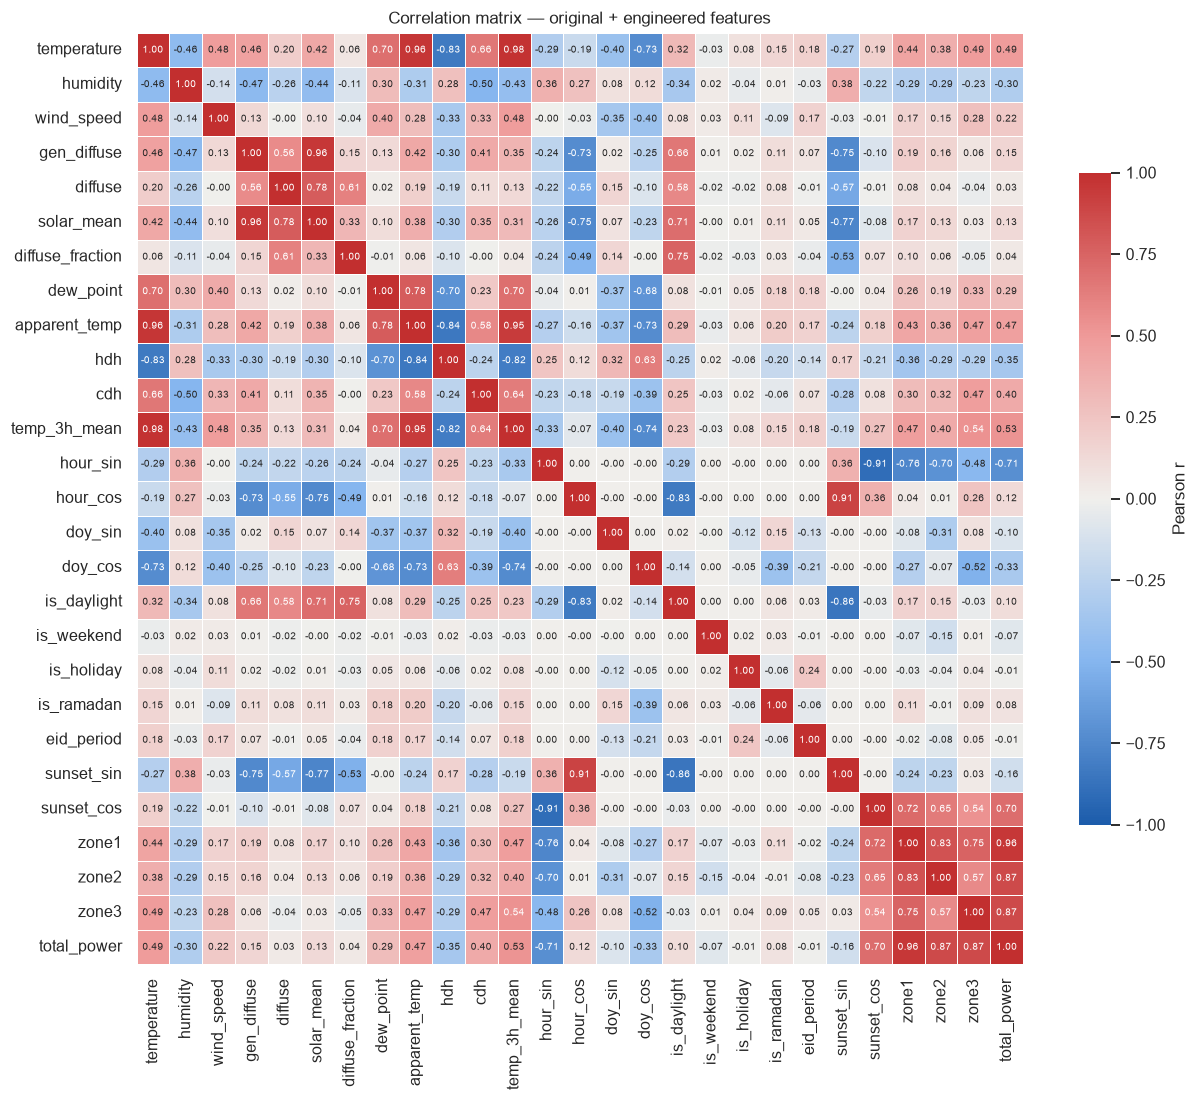

r
temperature   apparent_temp  0.962
              temp_3h_mean   0.980
gen_diffuse   solar_mean     0.956
apparent_temp temp_3h_mean   0.945
hour_sin      sunset_cos    -0.905
hour_cos      sunset_sin     0.905
zone1         total_power    0.959

In [17]:
NUM_CANDIDATES = ['temperature', 'humidity', 'wind_speed', 'gen_diffuse', 'diffuse', 'solar_mean',
                  'diffuse_fraction', 'dew_point', 'apparent_temp', 'hdh', 'cdh', 'temp_3h_mean',
                  'hour_sin', 'hour_cos', 'doy_sin', 'doy_cos', 'is_daylight', 'is_weekend',
                  'is_holiday', 'is_ramadan', 'eid_period', 'sunset_sin', 'sunset_cos', 'zone1', 'zone2', 'zone3', 'total_power']
corr = df[NUM_CANDIDATES].corr()
fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(corr, cmap='div_br', vmin=-1, vmax=1, center=0, annot=True, fmt='.2f', annot_kws={'size': 6.5},
            linewidths=0.5, linecolor='white', cbar_kws={'label': 'Pearson r', 'shrink': 0.7}, ax=ax)
ax.set_title('Correlation matrix — original + engineered features')
save_fig('03_feature_correlation_heatmap'); plt.show()

# Redundant pairs
pairs = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack()
pairs[pairs.abs() > 0.9].round(3).rename('r').to_frame()

**Inference (redundancy):**
- `solar_mean` ≈ `gen_diffuse` and `apparent_temp`/`temp_3h_mean` ≈ `temperature` — keep one of each group by relevance (next cell).
- `sunset_sin/cos` vs `hour_cos/sin` (|r| = 0.905): flagged here, but kept after the KNN check in 4.3.
- `gen_diffuse` vs `diffuse` is only moderately correlated, so the two flows carry **different** information (total vs scattered light) → both kept, plus their ratio `diffuse_fraction`.
- Zones correlate 0.57–0.83 with each other: related but not interchangeable → all three kept for ARM.

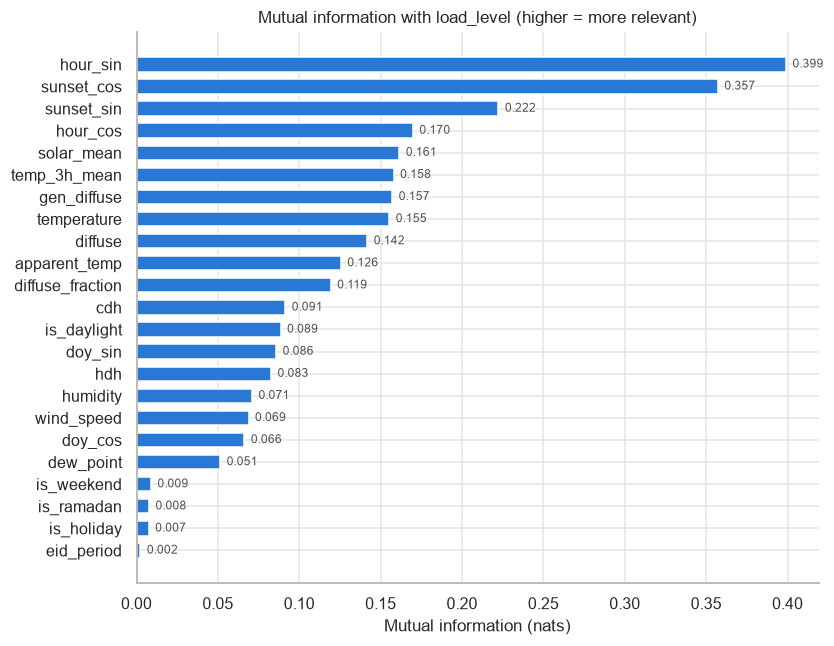

,hour_sin,sunset_cos,sunset_sin,hour_cos,solar_mean,temp_3h_mean,gen_diffuse,temperature,diffuse,apparent_temp,diffuse_fraction,cdh,is_daylight,doy_sin,hdh,humidity,wind_speed,doy_cos,dew_point,is_weekend,is_ramadan,is_holiday,eid_period
MI,0.399,0.357,0.222,0.17,0.161,0.158,0.157,0.155,0.142,0.126,0.119,0.091,0.089,0.086,0.083,0.071,0.069,0.066,0.051,0.009,0.008,0.007,0.002


In [18]:
# Relevance: mutual information of non-power features with load_level (20k-row sample for speed)
KNN_CANDIDATES = [c for c in NUM_CANDIDATES if c not in ZONES + ['total_power']]
s = df.sample(20000, random_state=SEED)
mi = pd.Series(mutual_info_classif(s[KNN_CANDIDATES], s.load_level, random_state=SEED),
               index=KNN_CANDIDATES).sort_values()

fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(mi.index, mi.values, color=CAT[0], height=0.65)
for i, v in enumerate(mi.values):
    ax.text(v + 0.004, i, f'{v:.3f}', va='center', fontsize=8, color='#52514e')
ax.set(title='Mutual information with load_level (higher = more relevant)', xlabel='Mutual information (nats)')
save_fig('04_mutual_information_ranking'); plt.show()
mi.sort_values(ascending=False).round(3).to_frame('MI').T

In [19]:
# Final task-relevant attribute sets
REDUNDANT_DROP = ['solar_mean', 'apparent_temp', 'temp_3h_mean']   # |r|>0.9 twins of kept features
LOW_MI = mi[mi < 0.01].index.tolist()                               # near-zero relevance
KNN_FEATURES = [c for c in mi.sort_values(ascending=False).index if c not in REDUNDANT_DROP + LOW_MI]

ARM_ATTRS = ['temperature', 'humidity', 'wind_regime', 'solar_level', 'part_of_day', 'season',
             'day_type', 'is_ramadan', 'zone1', 'zone2', 'zone3', 'total_power']
DIANA_INPUT = '364 days x 24 hourly mean total_power (+ day labels for profiling)'

print('Dropped as redundant:', [c for c in REDUNDANT_DROP if c in KNN_CANDIDATES])
print('Dropped as low-MI   :', LOW_MI)
print('KNN features        :', KNN_FEATURES)
print('ARM attributes      :', ARM_ATTRS)
print('DIANA input         :', DIANA_INPUT)

Dropped as redundant: ['solar_mean', 'apparent_temp', 'temp_3h_mean']
Dropped as low-MI   : ['eid_period', 'is_holiday', 'is_ramadan', 'is_weekend']
KNN features        : ['hour_sin', 'sunset_cos', 'sunset_sin', 'hour_cos', 'gen_diffuse', 'temperature', 'diffuse', 'diffuse_fraction', 'cdh', 'is_daylight', 'doy_sin', 'hdh', 'humidity', 'wind_speed', 'doy_cos', 'dew_point']
ARM attributes      : ['temperature', 'humidity', 'wind_regime', 'solar_level', 'part_of_day', 'season', 'day_type', 'is_ramadan', 'zone1', 'zone2', 'zone3', 'total_power']
DIANA input         : 364 days x 24 hourly mean total_power (+ day labels for profiling)


**Inference (relevance):** time of day is the strongest driver of load level (`hour_sin` 0.40, `sunset_cos` 0.36), then solar radiation and temperature-type features, then season. Weekend/holiday/Ramadan flags have ~0 MI over the whole year (they affect few readings), so they are dropped from KNN but **kept** for ARM and DIANA, where they label specific days.

### 4.3 Feature validation — do the extra features actually help?
MI scores one feature at a time. This check scores the **whole set** with KNN (k = 15, scaled), 5-fold CV with **whole weeks held out** together so neighbouring timestamps cannot leak. Metric: macro-F1. A candidate is kept only if it improves the score beyond noise (~±0.005).

In [20]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score, GroupKFold

s = df.sample(20000, random_state=SEED).copy()
s['ramadan_night'] = ((s.is_ramadan == 1) & (s.hour < 6)).astype(int)
weeks = s.datetime.dt.isocalendar().week
no_sun = [c for c in KNN_FEATURES if not c.startswith('sunset')]

def knn_f1(cols):
    pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15))
    return cross_val_score(pipe, s[cols], s.load_level, cv=GroupKFold(5), groups=weeks, scoring='f1_macro').mean()

variants = {'Without sunset features (MI set only)': no_sun,
            'Selected set (with sunset_sin/cos)': KNN_FEATURES,
            '+ is_ramadan, is_weekend': KNN_FEATURES + ['is_ramadan', 'is_weekend'],
            '+ ramadan_night (interaction)': KNN_FEATURES + ['ramadan_night'],
            '+ eid_period': KNN_FEATURES + ['eid_period']}
val = pd.Series({k: knn_f1(v) for k, v in variants.items()}, name='macro_F1').round(4)
val.to_frame().assign(change_vs_without_sunset=(val - val.iloc[0]).round(4))

,macro_F1,change_vs_without_sunset
Without sunset features (MI set only),0.8461,0.0000
Selected set (with sunset_sin/cos),0.8582,0.0121
"+ is_ramadan, is_weekend",0.8574,0.0113
+ ramadan_night (interaction),0.8612,0.0151
+ eid_period,0.8590,0.0129


**Inference (validation):**
- **Sunset features: +0.012 macro-F1** (0.846 → 0.858) → **kept**. `sunset_cos` and `hour_sin` cross the redundancy screen (|r| = 0.905), but together they place a reading against both the clock and that day's sunset (17:30 in winter → 20:50 in summer), which neither does alone. Here the validation result overrides the |r| screen.
- `ramadan_night`: +0.003 over the selected set — within noise → not added. ARM finds the `{Ramadan, Night}` pattern on its own.
- `is_ramadan`, `is_weekend` (−0.001) and `eid_period` (+0.001): no gain → this confirms the MI decision. They stay as **ARM items / DIANA day labels**, where they describe specific days.
- Final KNN set = MI-selected features + `sunset_sin/cos`.

## 5. Data Transformation
### 5.1 Skew correction
Irradiance is right-skewed (many zeros + long tail). `log1p` compresses the tail so distance-based KNN is not dominated by a few bright readings.

In [21]:
SKEWED = ['gen_diffuse', 'diffuse']
for c in SKEWED:
    df[f'log_{c}'] = np.log1p(df[c])
pd.DataFrame({'skew_raw': df[SKEWED].skew(),
              'skew_log1p': df[[f'log_{c}' for c in SKEWED]].skew().values}).round(2)

,skew_raw,skew_log1p
gen_diffuse,1.31,0.20
diffuse,2.46,0.21


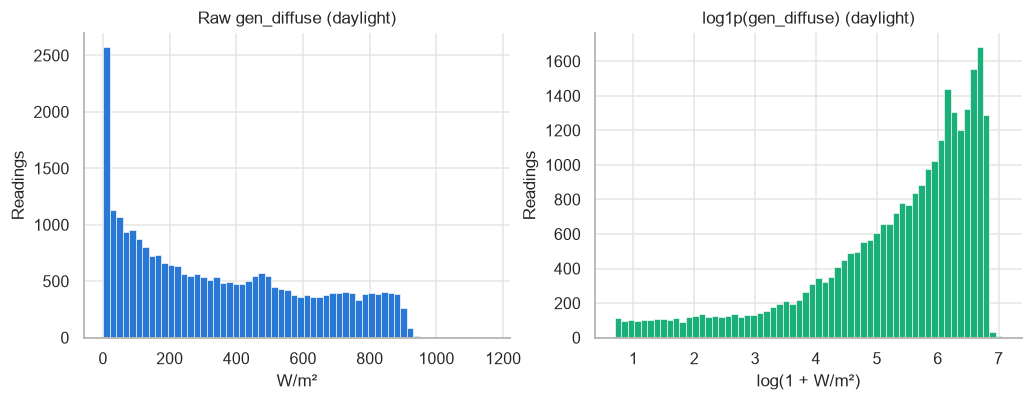

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
day_rows = df.is_daylight == 1
axes[0].hist(df.loc[day_rows, 'gen_diffuse'], bins=60, color=CAT[0], edgecolor='white', linewidth=0.4)
axes[0].set(title='Raw gen_diffuse (daylight)', xlabel='W/m²', ylabel='Readings')
axes[1].hist(df.loc[day_rows, 'log_gen_diffuse'], bins=60, color=CAT[2], edgecolor='white', linewidth=0.4)
axes[1].set(title='log1p(gen_diffuse) (daylight)', xlabel='log(1 + W/m²)', ylabel='Readings')
save_fig('05_log_transform_irradiance'); plt.show()

In [23]:
# Use log versions in KNN in place of raw flows
KNN_FEATURES = [f'log_{c}' if c in SKEWED else c for c in KNN_FEATURES]
print(KNN_FEATURES)

['hour_sin', 'sunset_cos', 'sunset_sin', 'hour_cos', 'log_gen_diffuse', 'temperature', 'log_diffuse', 'diffuse_fraction', 'cdh', 'is_daylight', 'doy_sin', 'hdh', 'humidity', 'wind_speed', 'doy_cos', 'dew_point']


### 5.2 Normalisation
KNN uses Euclidean distance, so features must share a scale. Both standard methods shown below. The KNN notebook fits the scaler **on training data only** (inside a Pipeline) to avoid leakage.

In [24]:
X = df[KNN_FEATURES]
minmax = (X - X.min()) / (X.max() - X.min())          # v' = (v - min) / (max - min)
zscore = (X - X.mean()) / X.std()                     # v' = (v - mean) / std
pd.concat({'raw_range': X.max() - X.min(), 'minmax_range': minmax.max() - minmax.min(),
           'z_mean': zscore.mean().round(3), 'z_std': zscore.std().round(3)}, axis=1).round(3)

,raw_range,minmax_range,z_mean,z_std
hour_sin,2.000,1.0,0.0,1.0
sunset_cos,2.000,1.0,-0.0,1.0
sunset_sin,2.000,1.0,-0.0,1.0
hour_cos,2.000,1.0,-0.0,1.0
log_gen_diffuse,7.060,1.0,-0.0,1.0
temperature,36.763,1.0,-0.0,1.0
log_diffuse,6.843,1.0,-0.0,1.0
diffuse_fraction,1.500,1.0,0.0,1.0
cdh,16.010,1.0,-0.0,1.0
is_daylight,1.000,1.0,0.0,1.0


### 5.3 Discretisation → transactions (for DIC & COFI)
ARM needs categorical items. Each 10-min reading becomes one transaction, e.g. `{Temp=High, Hum=Low, Wind=Calm, Solar=High, Afternoon, Summer, Workday, Z1=High, …}`.
- Continuous → **equal-frequency tertiles** (Low/Med/High) so every item starts with ~33 % support (avoids empty itemsets at practical thresholds).
- Solar → `Dark` at night, else daylight median split (Low/High).
- Wind → its two natural regimes (Calm/Windy) — tertiles would fail on a bimodal variable.
- Flags (Ramadan) → item only when true.

In [25]:
BANDS = ['Low', 'Med', 'High']
def tertile(s): return pd.qcut(s, 3, labels=BANDS).astype(str)

day_med = df.loc[df.is_daylight == 1, 'gen_diffuse'].median()
df['solar_level'] = np.where(df.is_daylight == 0, 'Dark', np.where(df.gen_diffuse <= day_med, 'Low', 'High'))

items = pd.DataFrame({
    'Temp': tertile(df.temperature), 'Hum': tertile(df.humidity),
    'Wind': df.wind_regime, 'Solar': df.solar_level,
    'Z1': tertile(df.zone1), 'Z2': tertile(df.zone2), 'Z3': tertile(df.zone3), 'Total': tertile(df.total_power)})
items = items.apply(lambda c: c.name + '=' + c)       # prefix: 'Temp=High'
items['Time'] = df.part_of_day
items['Season'] = df.season
items['Day'] = df.day_type
items['Ramadan'] = np.where(df.is_ramadan == 1, 'Ramadan', '')

transactions = [[i for i in row if i] for row in items.to_numpy()]
print('Transactions:', len(transactions), '| distinct items:', len({i for t in transactions for i in t}),
      '| avg length:', round(np.mean([len(t) for t in transactions]), 2))
transactions[:3]

Transactions: 52416 | distinct items: 35 | avg length: 11.08


[['Temp=Low',
  'Hum=Med',
  'Wind=Calm',
  'Solar=Dark',
  'Z1=Med',
  'Z2=Low',
  'Z3=High',
  'Total=Med',
  'Night',
  'Winter',
  'Holiday'],
 ['Temp=Low',
  'Hum=Med',
  'Wind=Calm',
  'Solar=Dark',
  'Z1=Med',
  'Z2=Med',
  'Z3=High',
  'Total=Med',
  'Night',
  'Winter',
  'Holiday'],
 ['Temp=Low',
  'Hum=Med',
  'Wind=Calm',
  'Solar=Dark',
  'Z1=Med',
  'Z2=Med',
  'Z3=High',
  'Total=Med',
  'Night',
  'Winter',
  'Holiday']]

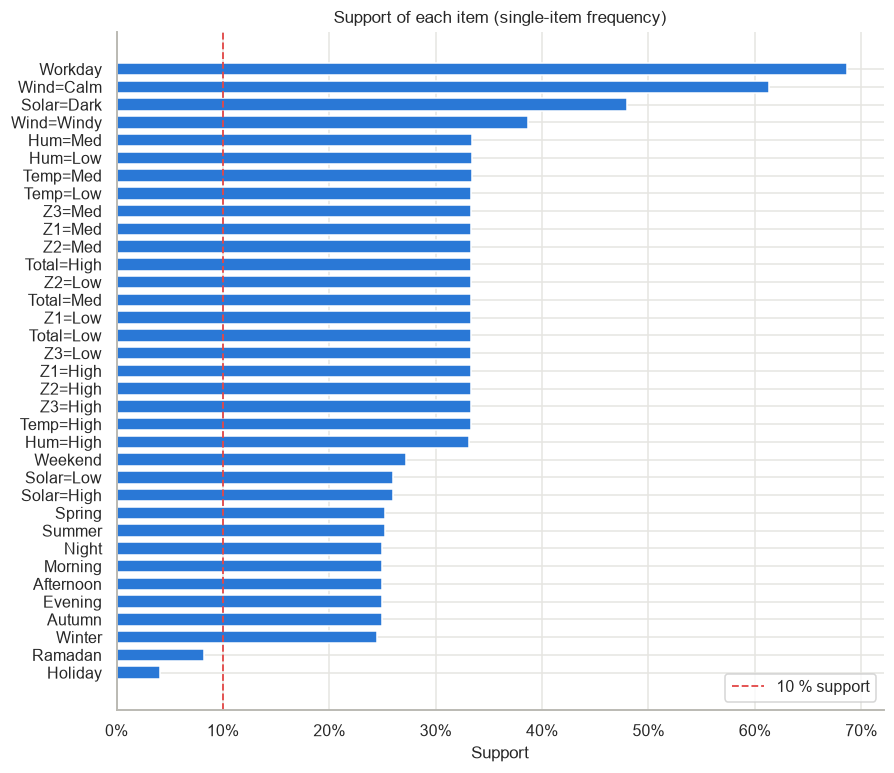

Min / max item support: 0.041 / 0.687


In [26]:
# Item supports: guides the min-support choice for DIC/COFI (pitfall: too high -> 0 itemsets)
sup = pd.Series([i for t in transactions for i in t]).value_counts() / len(transactions)
fig, ax = plt.subplots(figsize=(9, 8))
sup_sorted = sup.sort_values()
ax.barh(sup_sorted.index, sup_sorted.values, color=CAT[0], height=0.7)
ax.axvline(0.10, color=CAT[7], ls='--', lw=1.2, label='10 % support')
ax.set(title='Support of each item (single-item frequency)', xlabel='Support')
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.legend(loc='lower right')
save_fig('06_item_support'); plt.show()
print('Min / max item support:', round(sup.min(), 3), '/', round(sup.max(), 3))

**Inference:** most items sit near 25–35 % support; rare ones are `Holiday` and `Ramadan`. A minimum support around **10 %** keeps the common patterns and lets pairs/triples survive; rare-event items need a lower threshold or will drop out (stated as an assumption in the DIC notebook).

### 5.4 Daily profiles (for DIANA)
- **Unit = one day.** DIANA needs an n × n distance matrix: 52,416 readings → ≈ 22 GB, hourly rows (8,736) → ≈ 0.6 GB plus O(n²) work per split, daily rows (364) → ≈ 1 MB. The question is also about **day types**, so a day is the natural unit.
- **Clustering input = 72 values per day**: hourly mean power of each zone (`z1_h00 … z3_h23`). Two days can have the same city total while different zones peak; keeping zones separate lets DIANA see that.
- The 24 city-total columns (`h00 … h23`) are kept for plotting only. Season, day type, Ramadan and Eid are **not** clustering inputs — they are used afterwards to interpret the groups.
- Day-level labels use **mode** where a day has many readings.

In [27]:
df['date'] = day
hourly = df.groupby(['date', 'hour']).total_power.mean().unstack()
hourly.columns = [f'h{h:02d}' for h in hourly.columns]

mode = lambda s: s.mode().iat[0]
daily = df.groupby('date').agg(
    month=('month', 'first'), season=('season', 'first'), day_type=('day_type', 'first'),
    is_ramadan=('is_ramadan', 'max'), eid_period=('eid_period', 'max'), temp_mean=('temperature', 'mean'), temp_max=('temperature', 'max'),
    wind_mode=('wind_regime', mode),                        # dominant wind regime of the day
    daily_mean=('total_power', 'mean'), daily_peak=('total_power', 'max'), load_factor=('load_factor', 'first'))
daily['peak_hour'] = hourly.to_numpy().argmax(axis=1)      # hour of the day's maximum

# 72 clustering columns: hourly mean per zone, ordered z1_h00..z1_h23, z2_h00.., z3_h00..
zone_hourly = df.groupby(['date', 'hour'])[ZONES].mean().unstack('hour')
zone_hourly.columns = [f'z{z[-1]}_h{h:02d}' for z, h in zone_hourly.columns]
ZONE_HOUR_COLS = [f'z{k}_h{h:02d}' for k in (1, 2, 3) for h in range(24)]
daily = daily.join(hourly).join(zone_hourly[ZONE_HOUR_COLS])

# Check: the three zone profiles add up to the city profile
recon = sum(daily[[f'z{k}_h{h:02d}' for h in range(24)]].to_numpy() for k in (1, 2, 3))
print('Zone columns sum to city columns:', np.allclose(recon, daily[hourly.columns].to_numpy()))
print(daily.shape, '| zone-hour columns:', len(ZONE_HOUR_COLS))
daily[['season', 'day_type', 'is_ramadan', 'z1_h00', 'z1_h20', 'z2_h20', 'z3_h20', 'h20']].head(3)

Zone columns sum to city columns: True
(364, 108) | zone-hour columns: 72


,season,day_type,is_ramadan,z1_h00,z1_h20,z2_h20,z3_h20,h20
date,,,,,,,,
2017-01-01,Winter,Holiday,0,29197.974683,40371.645568,25406.079028,26493.493978,92271.218575
2017-01-02,Winter,Workday,0,25303.291138,41096.708862,26782.370822,25642.409638,93521.489322
2017-01-03,Winter,Workday,0,25269.873417,42245.063290,27093.617022,26079.036145,95417.716457


### 5.5 Save outputs

In [28]:
KEEP = (['datetime', 'date'] + WEATHER + ZONES + ['total_power', 'hour', 'dayofweek', 'month', 'part_of_day',
        'season', 'day_type', 'is_weekend', 'is_holiday', 'is_ramadan', 'hour_sin', 'hour_cos', 'doy_sin',
        'doy_cos', 'solar_mean', 'is_daylight', 'diffuse_fraction', 'solar_level', 'wind_regime', 'dew_point',
        'apparent_temp', 'hdh', 'cdh', 'temp_3h_mean', 'hrs_after_sunset', 'sunset_sin', 'sunset_cos', 'eid_period', 'log_gen_diffuse', 'log_diffuse', 'zone1_share',
        'zone2_share', 'zone3_share', 'zone_cv', 'total_ramp', 'total_1h_mean', 'load_factor', 'load_level'])
df[KEEP].to_csv(OUTPUTS / 'clean_features.csv', index=False)
(OUTPUTS / 'transactions.txt').write_text('\n'.join(','.join(t) for t in transactions))
daily.to_csv(OUTPUTS / 'daily_profiles.csv')
pd.Series({'KNN_FEATURES': ','.join(KNN_FEATURES), 'ARM_ATTRS': ','.join(ARM_ATTRS)}).to_csv(OUTPUTS / 'feature_sets.csv', header=False)
for f in ['clean_features.csv', 'transactions.txt', 'daily_profiles.csv', 'feature_sets.csv', 'cleaning_log.csv']:
    print(f'{f:22s} {(OUTPUTS / f).stat().st_size/1e6:6.2f} MB')

clean_features.csv      28.17 MB
transactions.txt         4.97 MB
daily_profiles.csv       0.64 MB
feature_sets.csv         0.00 MB
cleaning_log.csv         0.00 MB


## 6. Summary
| Step | What was done | Result |
|---|---|---|
| Cleaning | validity rules, Hampel spike filter, irradiance floor | no invalid values; few spikes fixed; night sensor noise removed |
| Why not IQR | IQR flags seasonal summer demand | rejected for removal — local filter used |
| Features | time, cyclical, calendar (holiday, Ramadan), weather physics, power shares, daily load factor | Ramadan pre-dawn load +30 %; row-mode zone dropped (no variance) |
| Selection | |r| > 0.9 redundancy + mutual information + KNN validation | sunset feature kept (helps KNN); Ramadan/weekend/Eid flags kept out of KNN (no gain) |
| Transformation | log1p, min-max / z-score, tertile discretisation, daily 24-h profiles | `transactions.txt`, `clean_features.csv`, `daily_profiles.csv` |